# 02 · Model results – segmentation, forecasting, churn, inventory, drift
Every number below is read from the artefacts written by `python -m retailpulse.train --stage all`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retailpulse import config
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
PAL = ["#7C5CFF", "#22D3EE", "#34D399", "#FBBF24", "#FB7185"]
P = config.DATA_PROC
def J(n): return json.loads((config.REPORTS / n).read_text())


## Segmentation (F-02)

In [2]:
sm = J("segmentation_metrics.json"); prof = pd.read_parquet(P / "segment_profile.parquet").sort_values("revenue_share", ascending=False)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in sm.items() if k != "pca_explained_variance"})
display(prof[["segment", "size", "revenue_share", "recency", "frequency", "monetary", "avg_order_value", "description"]].round(2))

{'k': 6, 'silhouette': 0.247, 'davies_bouldin': 1.276, 'calinski_harabasz': 1793.087, 'dbscan_eps': 0.992, 'dbscan_clusters': 2, 'dbscan_noise_share': 0.073, 'dbscan_silhouette': 0.319, 'n_customers': 5852, 'seconds': 2.656}


,segment,size,revenue_share,recency,frequency,monetary,avg_order_value,description
3,Champions,1160,0.73,22.0,13.0,5233.12,376.46,"Buy often, spend the most, bought very recentl..."
1,Loyal Regulars,1546,0.14,61.0,4.0,1266.54,293.44,"Frequent, recent buyers - upsell and cross-sell."
5,At Risk High-Value,726,0.04,418.0,3.0,776.15,249.29,"Used to spend a lot, gone quiet - win-back pri..."
0,New & Promising,1129,0.04,44.0,2.0,452.20,251.70,Recent first purchases - nurture into loyalty.
4,Fading Occasionals,59,0.02,277.0,1.0,376.70,172.26,"Infrequent, drifting away - light-touch remind..."
2,Lost / Hibernating,1232,0.02,436.0,1.0,223.20,188.45,Long inactive and low value - low-cost reactiv...


## Demand forecasting (F-03)

,split,model,mape_daily,wape_daily,mape_weekly,ape_30d_total
0,cv,naive,31.69,27.70,14.15,8.75
1,cv,prophet,32.08,26.31,13.68,7.18
2,cv,lstm_raw,29.26,26.12,15.09,12.48
3,cv,lstm,33.71,27.43,15.07,7.57
4,cv,ensemble,30.88,24.85,11.89,4.24
5,test,naive,23.13,22.93,13.80,14.56
6,test,prophet,21.45,19.28,12.68,3.09
7,test,lstm_raw,20.53,22.06,18.16,18.32
8,test,lstm,17.48,17.11,9.63,8.52
9,test,ensemble,19.52,18.11,11.18,5.26


ensemble weight on LSTM: 0.4 | LSTM calibration k: 1.12 | hold-out origin: 2011-11-10


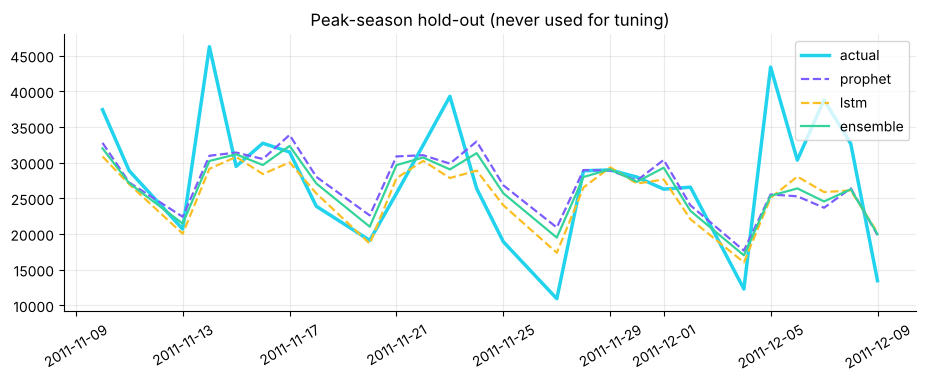

In [3]:
fm = J("forecast_metrics.json")
rows = []
for split in ("cv", "test"):
    for m, v in fm[split].items(): rows.append({"split": split, "model": m, **{k: round(x, 2) for k, x in v.items()}})
display(pd.DataFrame(rows))
print("ensemble weight on LSTM:", fm["w_lstm"], "| LSTM calibration k:", round(fm["k_lstm"], 3), "| hold-out origin:", fm["test_origin"])
bt = pd.read_parquet(P / "forecast_backtest.parquet"); t = bt[bt["is_test"]].sort_values("date")
plt.figure(figsize=(11, 3.6)); plt.plot(t["date"], t["actual"], lw=2.5, label="actual", color=PAL[1])
for k, c in (("prophet", PAL[0]), ("lstm", PAL[3]), ("ensemble", PAL[2])): plt.plot(t["date"], t[k], lw=1.6, ls="--" if k != "ensemble" else "-", label=k, color=c)
plt.legend(); plt.title("Peak-season hold-out (never used for tuning)"); plt.xticks(rotation=30); plt.show()

## Churn (F-04)

In [4]:
cm = J("churn_metrics.json"); b = pd.DataFrame(cm["benchmark"])
display(b[["model", "auc_roc", "auc_pr", "precision_top20", "lift_top20", "f1", "recall", "brier"]].round(3))
print("final:", {k: round(v, 3) for k, v in cm["final"].items()}); print("targets:", cm["targets"])
display(pd.read_parquet(P / "churn_shap_importance.parquet").head(10).round(4))

,model,auc_roc,auc_pr,precision_top20,lift_top20,f1,recall,brier
0,Logistic Regression,0.779,0.803,0.859,1.522,0.777,0.911,0.198
1,Random Forest,0.772,0.794,0.844,1.495,0.775,0.905,0.201
2,XGBoost (Optuna-tuned),0.799,0.818,0.883,1.564,0.786,0.870,0.190
3,XGBoost (final: train+valid refit),0.806,0.826,0.889,1.574,0.791,0.909,0.180


final: {'auc_roc': 0.806, 'auc_pr': 0.826, 'precision_top20': 0.889, 'recall_top20': 0.315, 'lift_top20': 1.574, 'f1': 0.791, 'precision': 0.7, 'recall': 0.909, 'brier': 0.18, 'threshold': 0.349, 'base_rate': 0.564}
targets: {'auc_min': 0.88, 'precision_top20_min': 0.75}


,feature,mean_abs_shap,seasonal_baseline
0,snap_cos,0.2846,True
1,monetary_180,0.2548,False
2,freq_180,0.2014,False
3,snap_sin,0.1509,True
4,n_skus,0.1395,False
5,days_to_xmas,0.1391,True
6,mean_gap,0.1261,False
7,tenure_days,0.1159,False
8,frequency,0.0953,False
9,days_since_first_to_second,0.0925,False


## Inventory (F-05)

In [5]:
im = J("inventory_metrics.json"); pol = pd.DataFrame(im["policy_summary"])
display(pol[["policy", "fill_rate_pct", "understock_pct_of_demand", "overstock_pct_of_demand", "lost_margin", "holding_cost", "total_cost"]].round(1))
print("median per-SKU 4-week WAPE %:", {k: round(v, 1) for k, v in im["sku_wape_median"].items()}); print(im["assumptions"])

,policy,fill_rate_pct,understock_pct_of_demand,overstock_pct_of_demand,lost_margin,holding_cost,total_cost
0,Hierarchical forecast (no buffer),75.4,24.6,18.1,242087.0,4831.4,246918.4
1,Moving average (no buffer),70.0,30.0,11.5,294845.9,3000.0,297845.9
2,Moving average + safety stock,85.6,14.4,35.1,136085.8,9493.2,145578.9
3,Per-SKU Prophet (no buffer),76.5,23.5,71.1,242972.6,23287.5,266260.1
4,RetailPulse (hierarchical + safety stock),87.4,12.6,48.6,117132.5,13132.0,130264.4


median per-SKU 4-week WAPE %: {'ma': 51.1, 'direct': 71.9, 'hier': 54.1}
{'stock': 'SIMULATED (no stock table in public dataset)', 'unit_cost_ratio': 0.6, 'holding_rate': 0.2, 'order_cost': 25.0}


## Drift & MLOps

In [6]:
dr = J("drift_summary.json"); print(json.dumps({k: dr[k] for k in ("current", "decision")}, indent=1, default=str)[:1500])
display(pd.read_parquet(P / "drift_simulation.parquet").round(3))
print("batch benchmark:", J("batch_benchmark.json"))

{
 "current": {
  "n_features": 29,
  "n_alert": 4,
  "n_warn": 8,
  "share_drifted": 0.13793103448275862,
  "max_psi": 1.7219394243581767,
  "dataset_drift": false,
  "top": [
   {
    "feature": "tenure_days",
    "psi": 1.7219394243581767,
    "ks_stat": 0.5733082706766917,
    "ks_pvalue": 0.0,
    "ref_mean": 270.94402871877844,
    "cur_mean": 474.54032809295967,
    "status": "ALERT"
   },
   {
    "feature": "recency",
    "psi": 0.5860413938734765,
    "ks_stat": 0.23478772266899406,
    "ks_pvalue": 1.155546504831218e-247,
    "ref_mean": 125.04017089695621,
    "cur_mean": 200.7323991797676,
    "status": "ALERT"
   },
   {
    "feature": "monetary_trend",
    "psi": 0.3430864461482783,
    "ks_stat": 0.247779487651275,
    "ks_pvalue": 3.5033380394287077e-276,
    "ref_mean": 117.67301011437777,
    "cur_mean": 195.79859250389165,
    "status": "ALERT"
   },
   {
    "feature": "freq_trend",
    "psi": 0.2626388719477148,
    "ks_stat": 0.21335223233531295,
    "ks_pvalue":

,severity,n_features,n_alert,n_warn,share_drifted,max_psi,dataset_drift
0,0.0,29,4,8,0.138,1.722,False
1,0.2,29,5,9,0.172,1.722,False
2,0.4,29,6,8,0.207,1.722,False
3,0.6,29,6,9,0.207,1.722,False
4,0.8,29,8,8,0.276,1.722,False
5,1.0,29,9,10,0.310,1.722,True


batch benchmark: {'runs': [{'rows': 1067371, 'seconds': 2.54}, {'rows': 2134742, 'seconds': 5.33}, {'rows': 3202113, 'seconds': 7.32}], 'rows_per_second': 437447.131147541, 'extrapolated_10M_seconds': 22.8599053187692, 'note': 'full ETL transform + aggregation measured at 1-3x raw volume; 10M value is a linear extrapolation'}
